### Có dùng AI hỗ trợ
Công cụ: Google Gemini
Mục đích: Khảo sát tham số r và t trên ảnh bóng mờ (Mục 3.6.a).
Prompt: Viết code Python quét 5 giá trị radius và 3 giá trị t, tạo lưới ảnh trực quan cho thí nghiệm 3.6.a.
Đã sửa lại những gì: Điều chỉnh đường dẫn thư mục ảnh và tối ưu kích thước lưới ảnh cho phù hợp với màn hình hiển thị.

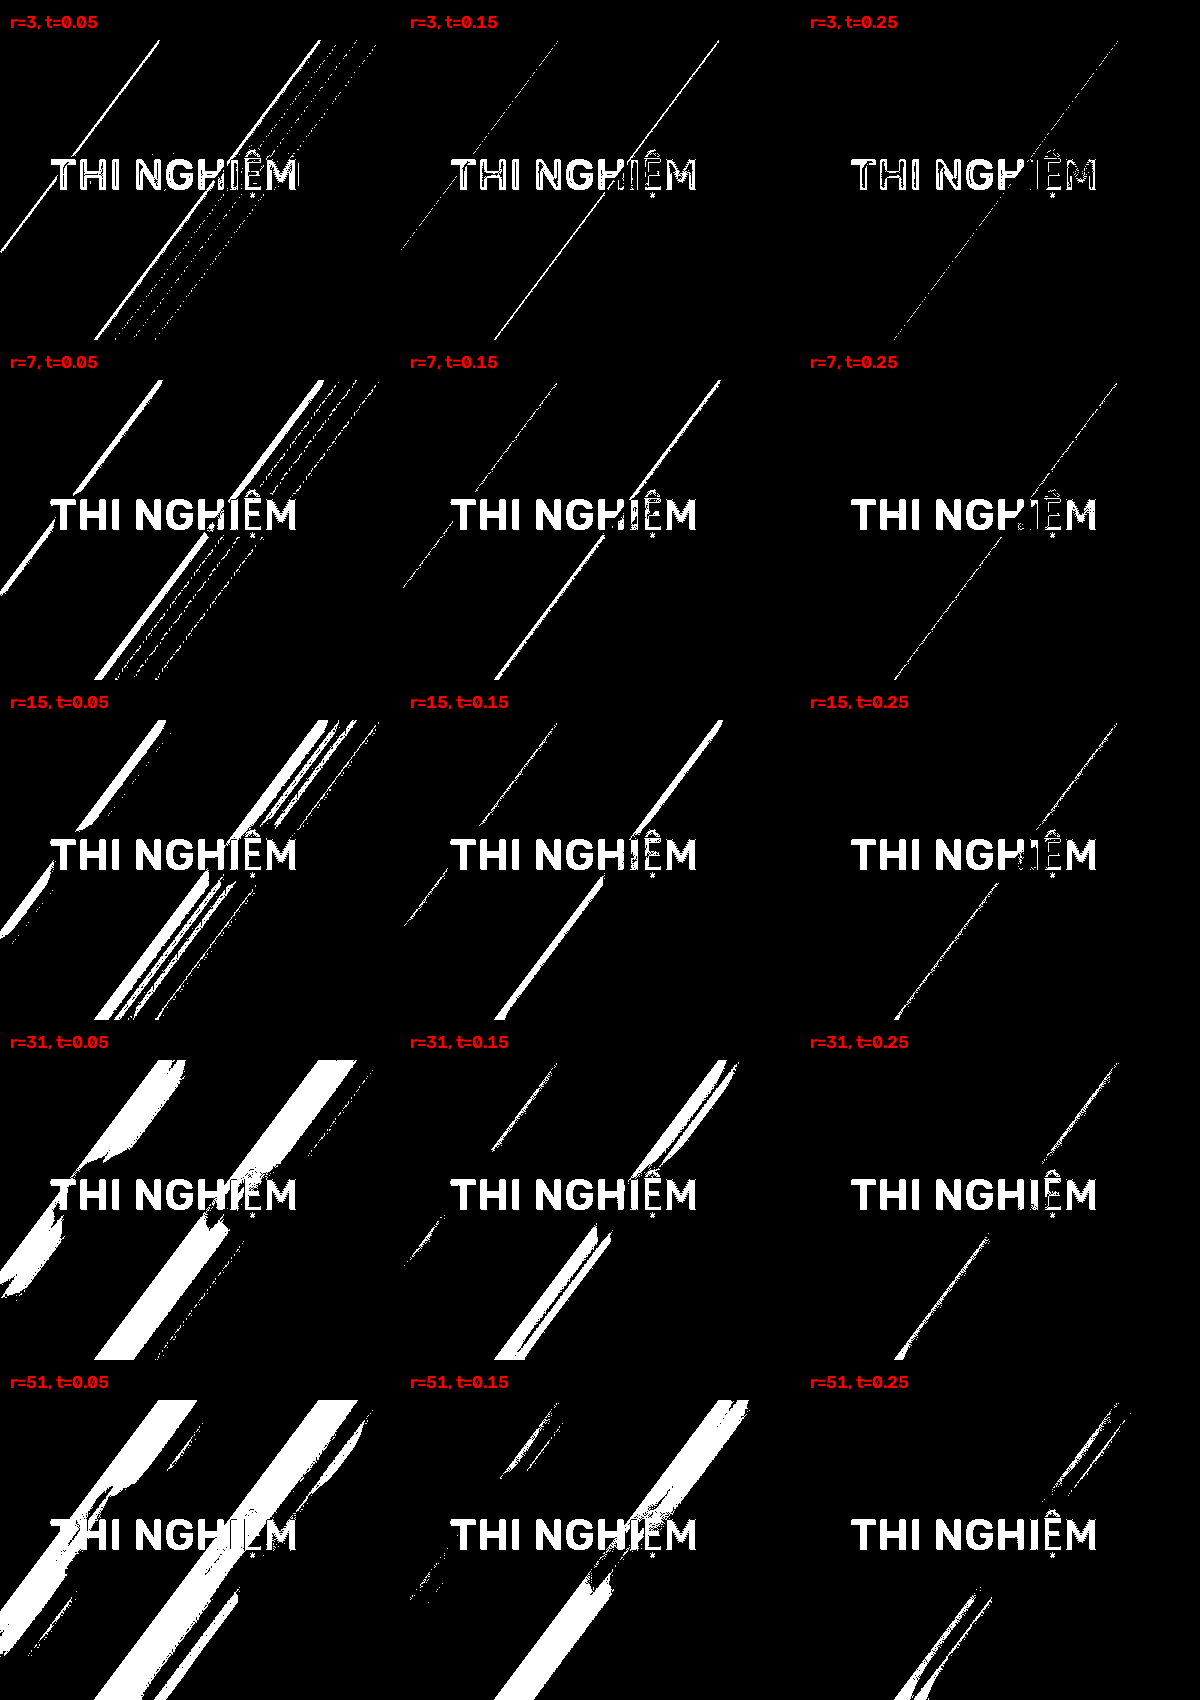

In [1]:
import cv2
import numpy as np
from pathlib import Path
from IPython.display import display, Image

img_dir = Path("images") if Path("images").exists() else Path("../images")
img_dir.mkdir(parents=True, exist_ok=True)

def integral_image(img):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    H, W = img.shape
    dtype = np.float64 if np.issubdtype(img.dtype, np.floating) else np.int64
    S = np.zeros((H + 1, W + 1), dtype=dtype)
    S[1:, 1:] = np.cumsum(np.cumsum(img, axis=0, dtype=dtype), axis=1, dtype=dtype)
    return S

def local_mean_std(img, radius):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    w = 2 * radius + 1
    w2 = w * w
    padded = np.pad(img, radius, mode='edge').astype(np.float64)
    S1 = integral_image(padded)
    S2 = integral_image(padded ** 2)
    sum1 = S1[w:, w:] - S1[:-w, w:] - S1[w:, :-w] + S1[:-w, :-w]
    sum2 = S2[w:, w:] - S2[:-w, w:] - S2[w:, :-w] + S2[:-w, :-w]
    mean = sum1 / w2
    var = (sum2 / w2) - (mean ** 2)
    var = np.maximum(var, 0.0)
    std = np.sqrt(var)
    return mean, std

def adaptive_threshold(img, radius=15, method='bradley', t=0.15, k=0.34, R=128.0):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    mean, std = local_mean_std(img, radius)
    if method.lower() == 'bradley':
        T = mean * (1.0 - t)
    elif method.lower() == 'sauvola':
        T = mean * (1.0 + k * ((std / R) - 1.0))
    else:
        raise ValueError("Phương pháp không hợp lệ!")
    binary = np.where(img.astype(np.float64) < T, 255, 0).astype(np.uint8)
    return binary

shadow_path = img_dir / "paper_shadow.jpg"
if shadow_path.exists():
    img = cv2.imread(str(shadow_path), cv2.IMREAD_GRAYSCALE)
    h, w = img.shape
    img_res = cv2.resize(img, (400, int(h * (400 / w))))

    radii_sweep = [3, 7, 15, 31, 51]
    t_sweep = [0.05, 0.15, 0.25]

    grid_images = []
    for r in radii_sweep:
        row_cells = []
        for t_val in t_sweep:
            res = adaptive_threshold(img_res, radius=r, method='bradley', t=t_val)
            bgr = cv2.cvtColor(res, cv2.COLOR_GRAY2BGR)
            canvas = np.zeros((bgr.shape[0] + 40, bgr.shape[1], 3), dtype=np.uint8)
            canvas[40:, :] = bgr
            cv2.putText(canvas, f"r={r}, t={t_val}", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
            row_cells.append(canvas)
        grid_images.append(np.hstack(row_cells))

    param_path = img_dir / "param_sweep_effect.png"
    cv2.imwrite(str(param_path), np.vstack(grid_images))
    display(Image(str(param_path)))

### Có dùng AI hỗ trợ
Công cụ: Google Gemini
Mục đích: So sánh 4 phương pháp ngưỡng hóa trên ảnh bóng mờ (Mục 3.6.b).
Prompt: Viết code so sánh ngưỡng cố định, Otsu, Bradley và Sauvola trên cùng một ảnh bóng mờ và ghép thành băng hình ngang.
Đã sửa lại những gì: Căn chỉnh lại kích thước canvas ngang và nhãn tên các phương pháp cho dễ đọc.

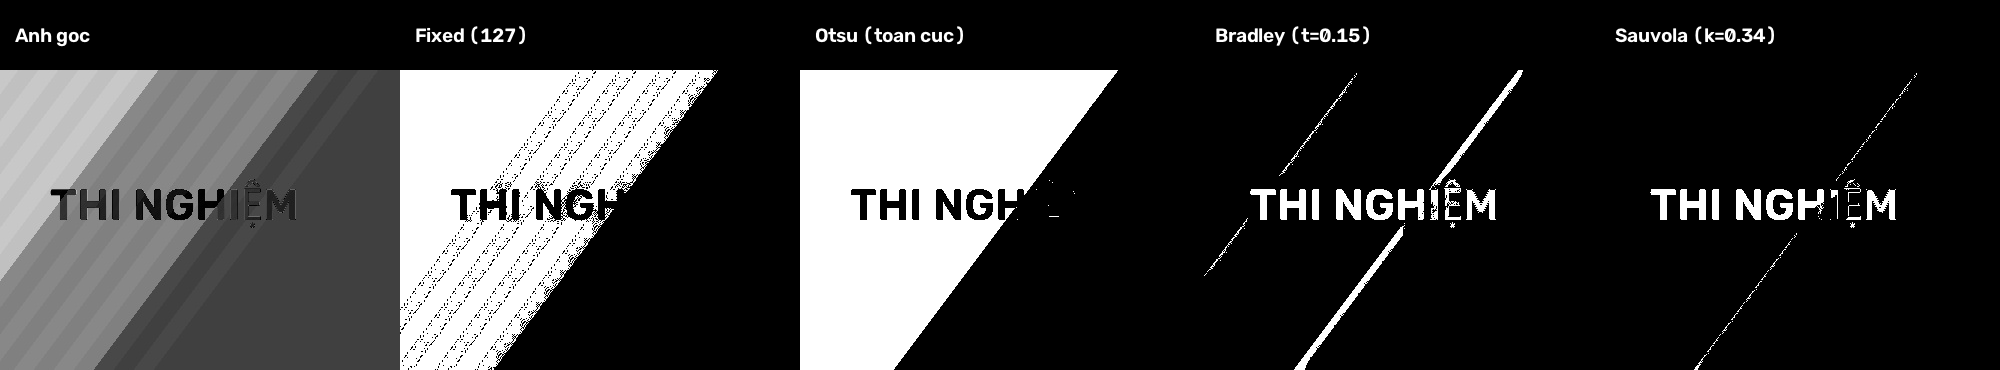

In [2]:
if shadow_path.exists():
    shadow_img = cv2.imread(str(shadow_path), cv2.IMREAD_GRAYSCALE)
    
    _, res_fixed = cv2.threshold(shadow_img, 127, 255, cv2.THRESH_BINARY)
    _, res_otsu = cv2.threshold(shadow_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    res_bradley = adaptive_threshold(shadow_img, radius=15, method='bradley', t=0.15)
    res_sauvola = adaptive_threshold(shadow_img, radius=15, method='sauvola', k=0.34, R=128.0)
    
    c_list = [cv2.cvtColor(x, cv2.COLOR_GRAY2BGR) for x in [shadow_img, res_fixed, res_otsu, res_bradley, res_sauvola]]
    H_i, W_i = shadow_img.shape
    comp_canvas = np.zeros((H_i + 70, W_i * 5, 3), dtype=np.uint8)
    
    for i, c in enumerate(c_list):
        comp_canvas[70:, i*W_i:(i+1)*W_i] = c
        
    labels = ["Anh goc", "Fixed (127)", "Otsu (toan cuc)", "Bradley (t=0.15)", "Sauvola (k=0.34)"]
    for i, lbl in enumerate(labels):
        cv2.putText(comp_canvas, lbl, (i*W_i + 15, 42), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2)
        
    comp_path = img_dir / "four_methods_comparison.png"
    cv2.imwrite(str(comp_path), comp_canvas)
    display(Image(str(comp_path)))

### Có dùng AI hỗ trợ
Công cụ: Google Gemini
Mục đích: Vẽ biểu đồ độ phức tạp thời gian chạy thang log (Mục 3.4 & 3.6.c).
Prompt: Viết code đo thời gian thực thi của 3 phương pháp tính trung bình cục bộ và vẽ biểu đồ log-log theo bán kính r.
Đã sửa lại những gì: Cấu hình lại thang log base 2 cho trục x và định dạng nhãn chú thích biểu đồ.

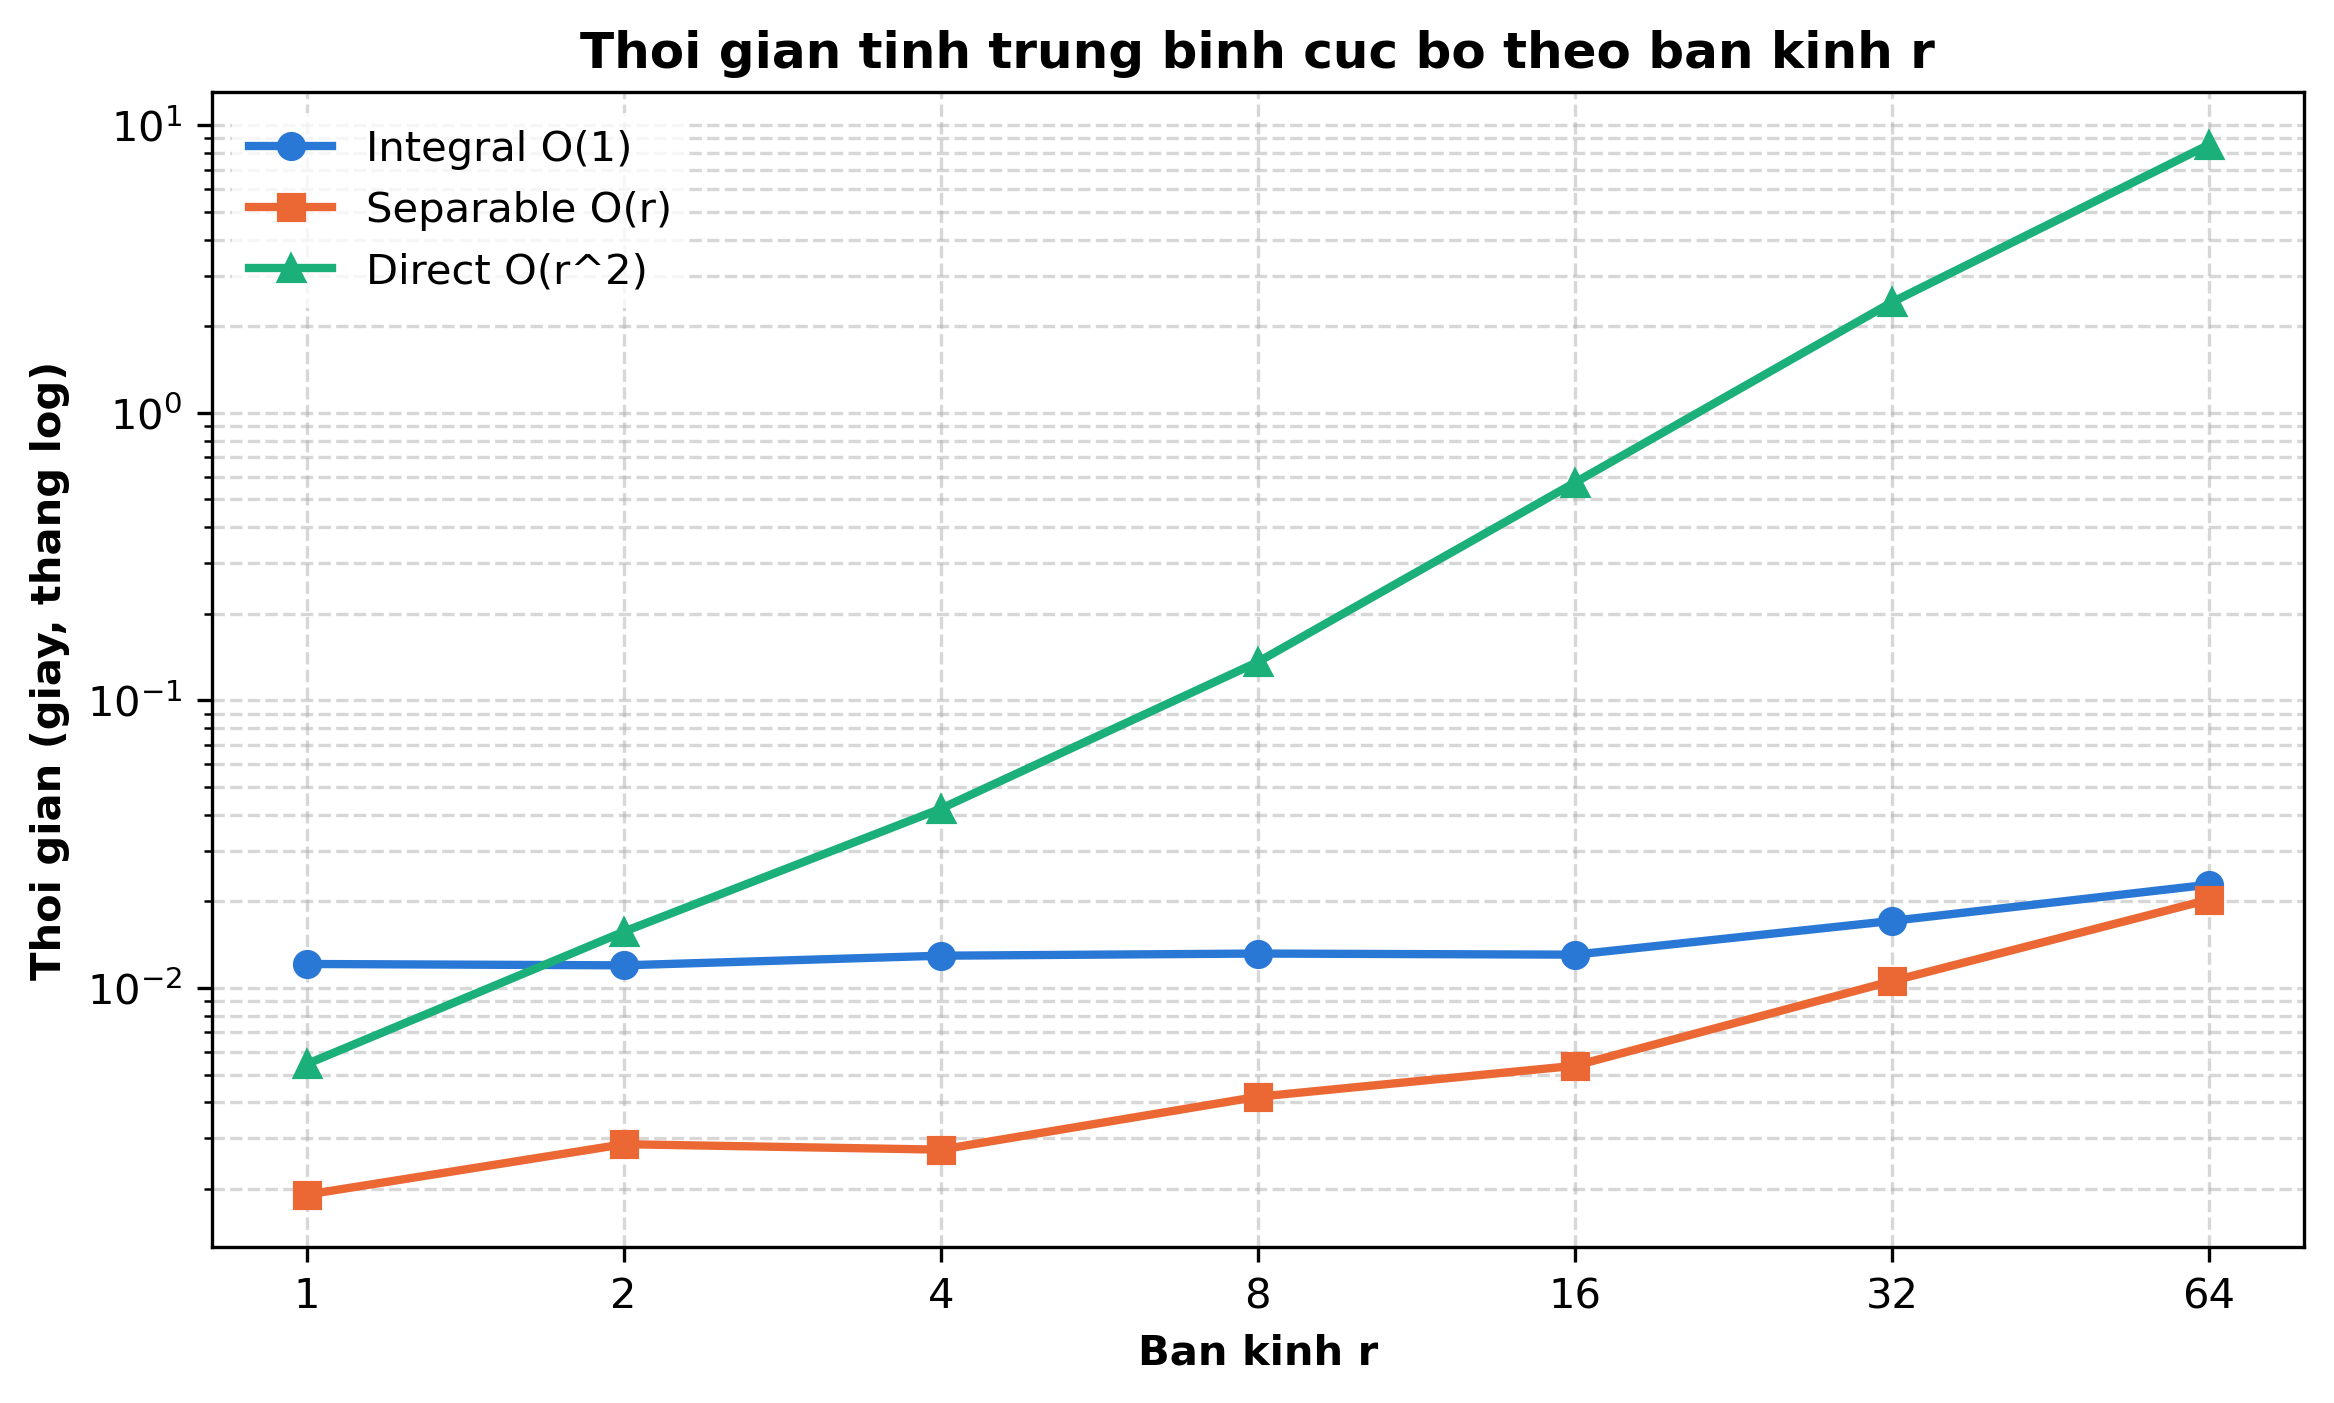

In [3]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import time

def separable_filter_1d_numpy(img, radius):
    w = 2 * radius + 1
    H, W = img.shape
    padded = np.pad(img, radius, mode='edge').astype(np.float64)
    rows = np.zeros((H + 2 * radius, W), dtype=np.float64)
    for dx in range(w):
        rows += padded[:, dx:dx + W]
    out = np.zeros((H, W), dtype=np.float64)
    for dy in range(w):
        out += rows[dy:dy + H, :]
    return out / (w * w)

def convolve2d(img, kernel):
    h_k, w_k = kernel.shape
    pad_h, pad_w = h_k // 2, w_k // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge').astype(np.float64)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for dy in range(h_k):
        for dx in range(w_k):
            out += kernel[dy, dx] * padded[dy:dy + H, dx:dx + W]
    return out

def bench(fn, repeat=3):
    best = float('inf')
    for _ in range(repeat):
        start = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - start)
    return best

radii_list = [1, 2, 4, 8, 16, 32, 64]
dummy_img = np.random.randint(0, 256, (512, 512), dtype=np.uint8)

t_integral, t_separable, t_direct = [], [], []
for r in radii_list:
    w = 2 * r + 1
    kernel_2d = np.ones((w, w), dtype=np.float64) / (w * w)
    t_integral.append(bench(lambda: local_mean_std(dummy_img, radius=r), 3))
    t_separable.append(bench(lambda: separable_filter_1d_numpy(dummy_img, radius=r), 3))
    t_direct.append(bench(lambda: convolve2d(dummy_img, kernel_2d), 1 if r > 16 else 2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(radii_list, t_integral, marker='o', label='Integral O(1)', color='#2a78d6', linewidth=2)
ax.plot(radii_list, t_separable, marker='s', label='Separable O(r)', color='#eb6834', linewidth=2)
ax.plot(radii_list, t_direct, marker='^', label='Direct O(r^2)', color='#1baf7a', linewidth=2)

ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xticks(radii_list)
ax.set_xticklabels([str(r) for r in radii_list])
ax.set_xlabel('Ban kinh r', fontweight='bold')
ax.set_ylabel('Thoi gian (giay, thang log)', fontweight='bold')
ax.set_title('Thoi gian tinh trung binh cuc bo theo ban kinh r', fontweight='bold')
ax.legend(loc="upper left", frameon=True, facecolor='white', edgecolor='none')
ax.grid(True, which="both", ls="--", alpha=0.5)

chart_path = img_dir / "time_complexity.png"
fig.savefig(str(chart_path), dpi=300, bbox_inches='tight')
plt.close(fig)
display(Image(str(chart_path)))